# State-space phase estimation

This notebook applies an independent Python implementation of the stochastic-oscillator model introduced by [Matsuda and Komaki (2017)](https://doi.org/10.1162/NECO_a_00916) and adapted for real-time state-space phase estimation (SSPE) by [Wodeyar et al. (2021)](https://elifesciences.org/articles/68803).

Each latent component is a damped, noise-driven planar oscillator,

$$x_{j,k}=a_jR(2\pi f_j/F_s)x_{j,k-1}+u_{j,k},$$

and the observation is the sum of the components' real coordinates plus measurement noise. The real and imaginary coordinates form an analytic signal whose phase is $\arg(x_1+i x_2)$. Parameters are estimated by expectation-maximization (EM), using Kalman filtering and Rauch--Tung--Striebel smoothing in each E-step.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks

import SSPE

%config InlineBackend.figure_format = 'retina'
cmap = plt.cm.viridis
rng = np.random.default_rng(12345)

## Hippocampal data

Use the sixth EEG channel and the same 4,000-point, stride-4 interval used by the Bayesian Hippocampal example.

In [2]:
n_channels = 31
raw_sampling_frequency = 1250.0  # Hz
stride = 4
sampling_frequency = raw_sampling_frequency / stride

data_path = Path('../Hippocampal/data/ec013.527.eeg')
eeg = np.fromfile(data_path, dtype=np.int16).reshape(-1, n_channels)

start = 10_000
n_samples = 4_000
stop = start + stride * n_samples
signal = eeg[start:stop:stride, 5].astype(float)
signal_centered = signal - signal.mean()
time = np.arange(n_samples) / sampling_frequency

print(f'{n_samples} samples over {time[-1]:.3f} s')
print(f'Sampling frequency: {sampling_frequency:g} Hz')

4000 samples over 12.797 s
Sampling frequency: 312.5 Hz


## Spectral initialization and EM fit

The implementation supports any number of oscillators. Here, three components are initialized from the strongest periodogram peaks in 0.5–4 Hz, 4–12 Hz, and 12–30 Hz. These are starting values only: EM estimates each frequency, damping factor, process variance, and the shared observation variance.

In [3]:
fft_values = np.fft.rfft(signal_centered)
frequencies = np.fft.rfftfreq(n_samples, d=1 / sampling_frequency)
power = np.abs(fft_values) ** 2
peak_indices, _ = find_peaks(power)

initialization_bands = [(0.5, 4.0), (4.0, 12.0), (12.0, 30.0)]
initial_frequencies = []
for lower, upper in initialization_bands:
    candidates = peak_indices[
        (frequencies[peak_indices] >= lower)
        & (frequencies[peak_indices] <= upper)
    ]
    if candidates.size == 0:
        raise RuntimeError(f'No spectral peak found in {lower:g}–{upper:g} Hz.')
    initial_frequencies.append(frequencies[candidates[np.argmax(power[candidates])]])

initial_frequencies = np.asarray(initial_frequencies)
print('Initial frequencies (Hz):', initial_frequencies)

Initial frequencies (Hz): [ 2.265625  8.359375 16.796875]


In [4]:
fit = SSPE.fit_sspe(
    signal_centered,
    sampling_frequency,
    initial_frequencies,
    initial_damping=0.99,
    max_iterations=600,
    frequency_tolerance=1e-3,
)

print(f"Converged: {fit['converged']} after {fit['n_iterations']} EM updates")
print('Fitted frequencies (Hz):', fit['frequencies'])
print('Fitted damping factors: ', fit['damping'])
print('Process variances:       ', fit['process_variances'])
print('Observation variance:    ', fit['observation_variance'])

Converged: True after 464 EM updates
Fitted frequencies (Hz): [ 3.29064017  8.25677155 15.46795052]
Fitted damping factors:  [0.94889342 0.99545443 0.83094722]
Process variances:        [ 4297.73387559  3289.57859103 32836.57542048]
Observation variance:     869.5966776542172


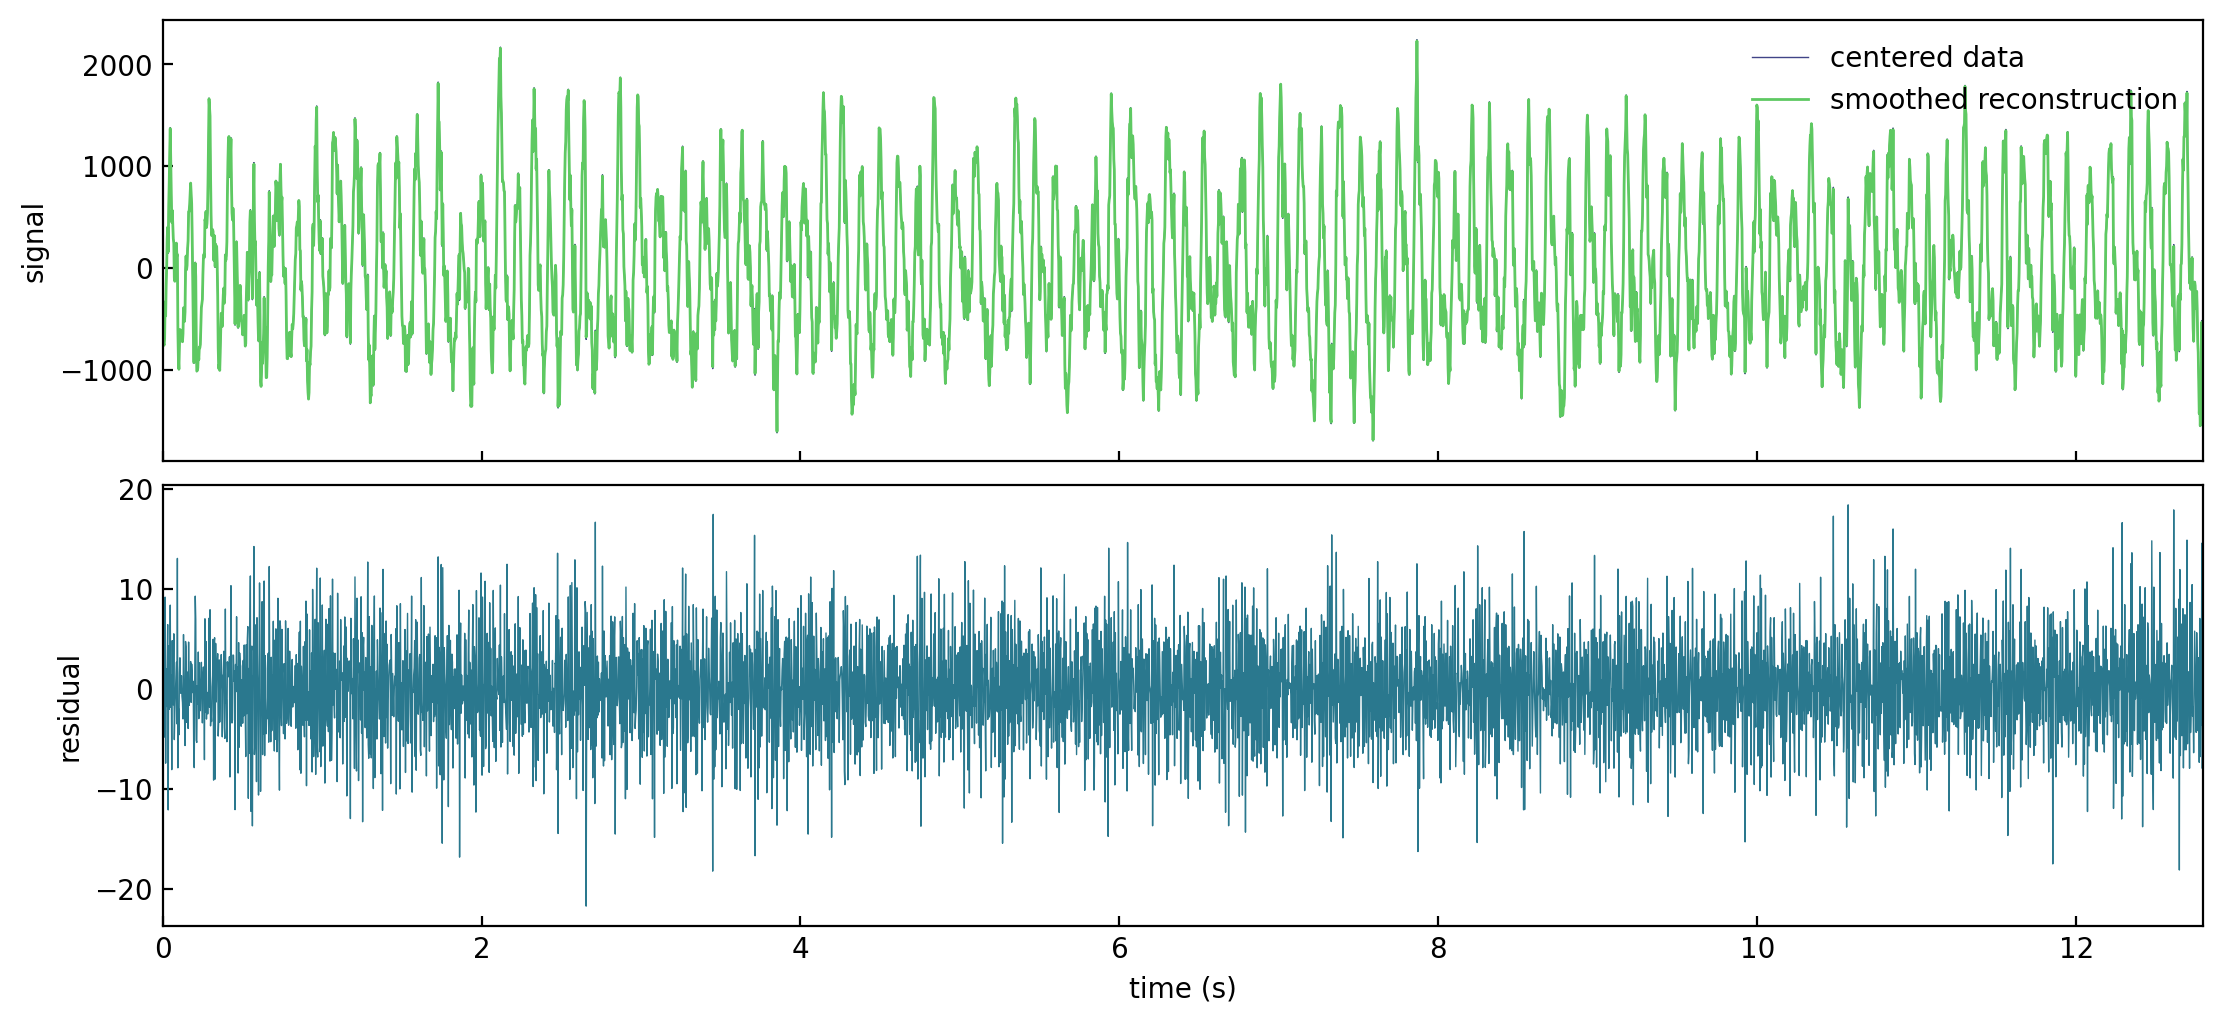

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True, constrained_layout=True)
axes[0].plot(time, signal_centered, color=cmap(0.2), lw=0.5, label='centered data')
axes[0].plot(
    time,
    fit['smoothed_reconstruction'],
    color=cmap(0.75),
    lw=1,
    label='smoothed reconstruction',
)
axes[0].set_ylabel('signal')
axes[0].legend(frameon=False)

residual = signal_centered - fit['smoothed_reconstruction']
axes[1].plot(time, residual, color=cmap(0.4), lw=0.5)
axes[1].set(xlabel='time (s)', ylabel='residual', xlim=(time[0], time[-1]))
for ax in axes:
    ax.tick_params(direction='in')
plt.show()

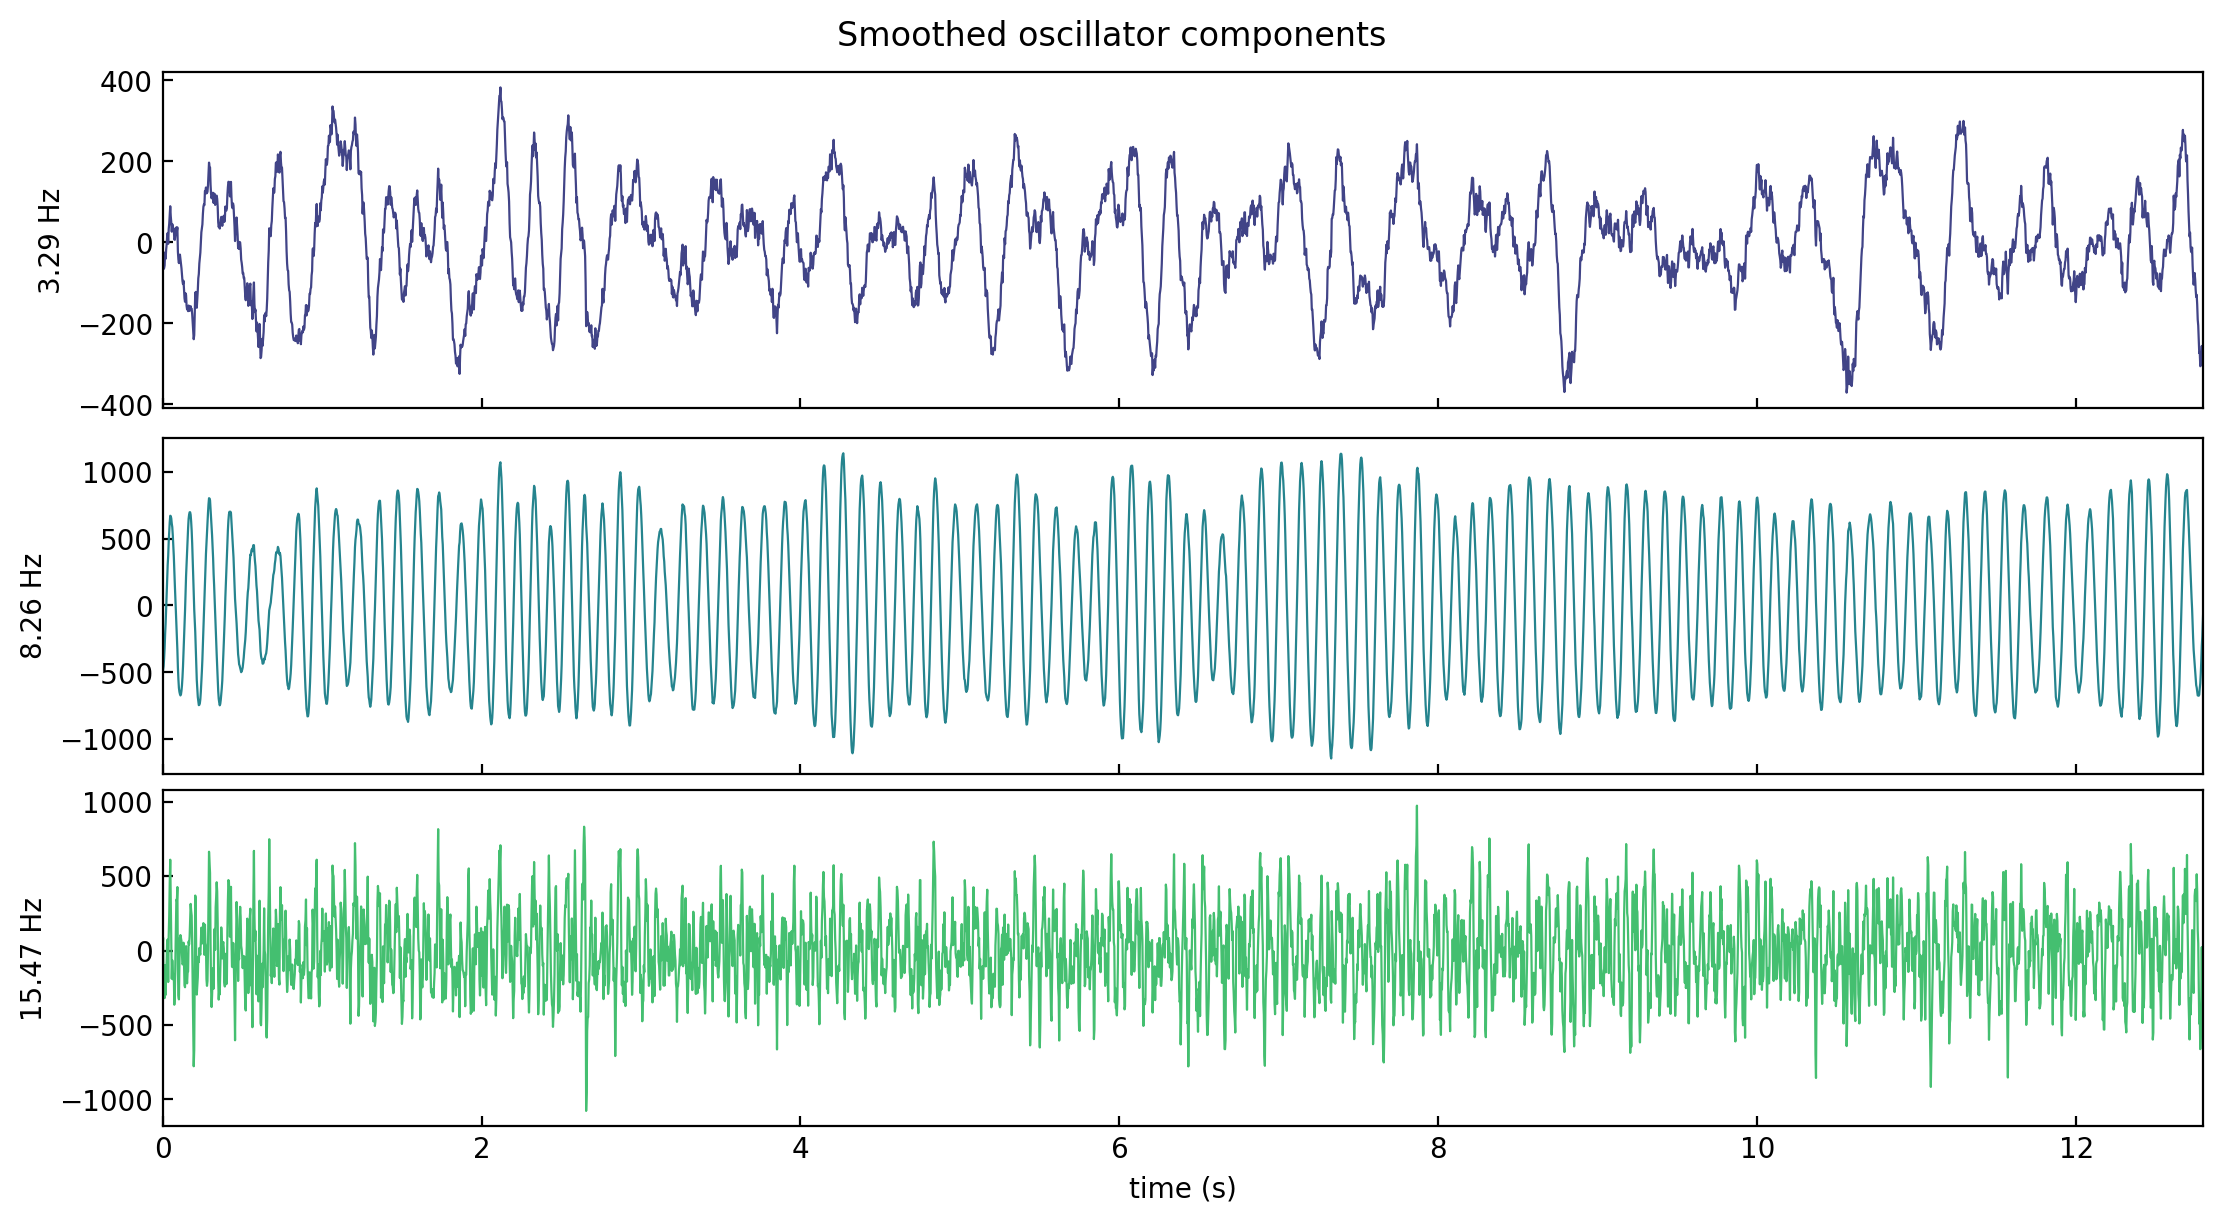

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True, constrained_layout=True)
for component, ax in enumerate(axes):
    ax.plot(
        time,
        fit['smoothed_components'][:, component],
        color=cmap(0.2 + 0.25 * component),
        lw=0.8,
    )
    ax.set_ylabel(f"{fit['frequencies'][component]:.2f} Hz")
    ax.tick_params(direction='in')
axes[-1].set(xlabel='time (s)', xlim=(time[0], time[-1]))
fig.suptitle('Smoothed oscillator components')
plt.show()

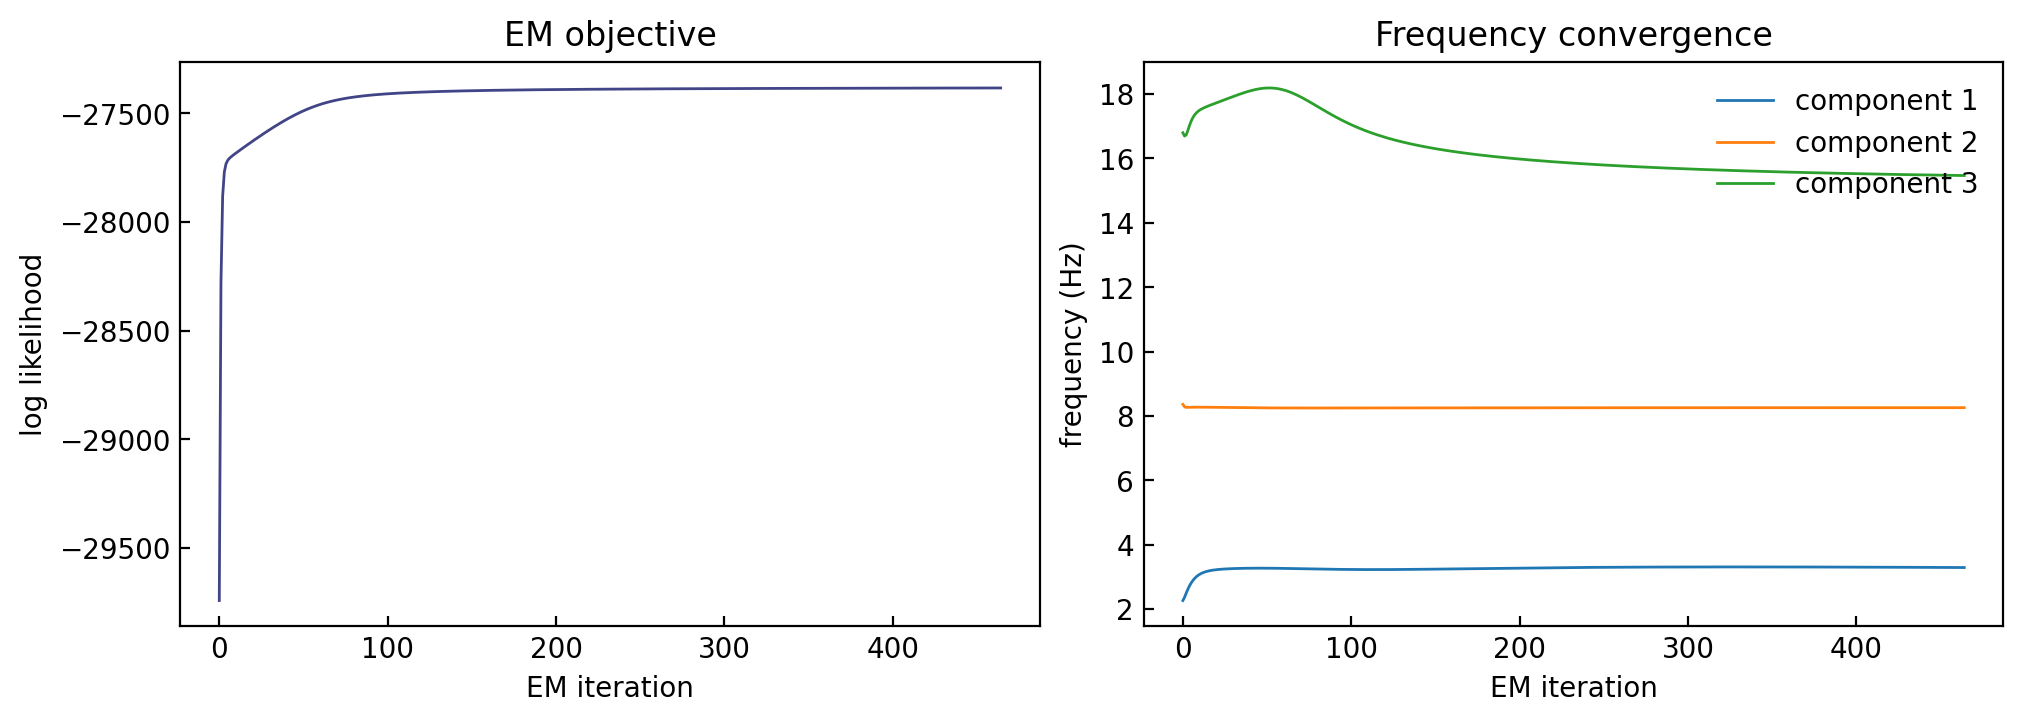

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
axes[0].plot(fit['likelihood_history'], color=cmap(0.2), lw=1)
axes[0].set(xlabel='EM iteration', ylabel='log likelihood', title='EM objective')

for component in range(fit['frequency_history'].shape[1]):
    axes[1].plot(
        fit['frequency_history'][:, component],
        lw=1,
        label=f'component {component + 1}',
    )
axes[1].set(xlabel='EM iteration', ylabel='frequency (Hz)', title='Frequency convergence')
axes[1].legend(frameon=False)
for ax in axes:
    ax.tick_params(direction='in')
plt.show()

## Theta phase and uncertainty

The primary estimate is the acausal RTS-smoothed phase. The forward-filtered phase is also available in `fit['filtered_phase']` for causal applications. Phase uncertainty is evaluated in two ways: a local delta-method approximation and direct seeded sampling from each smoothed bivariate Gaussian state. Monte Carlo intervals remain meaningful when the phase distribution becomes non-Gaussian at low amplitude.

In [8]:
theta_candidates = np.flatnonzero(
    (fit['frequencies'] >= 4.0) & (fit['frequencies'] <= 12.0)
)
if theta_candidates.size != 1:
    raise RuntimeError('Expected exactly one fitted component in the 4–12 Hz theta band.')
theta_component = theta_candidates.item()
theta_frequency_sspe = fit['frequencies'][theta_component]

delta_uncertainty = SSPE.phase_uncertainty_delta(
    fit['smoother']['smoothed_mean'],
    fit['smoother']['smoothed_covariance'],
    theta_component,
)
mc_uncertainty = SSPE.phase_uncertainty_monte_carlo(
    fit['smoother']['smoothed_mean'],
    fit['smoother']['smoothed_covariance'],
    theta_component,
    n_samples=2000,
    quantiles=(0.025, 0.25, 0.75, 0.975),
    rng=rng,
)
print(f'SSPE theta frequency: {theta_frequency_sspe:.6f} Hz')

SSPE theta frequency: 8.256772 Hz


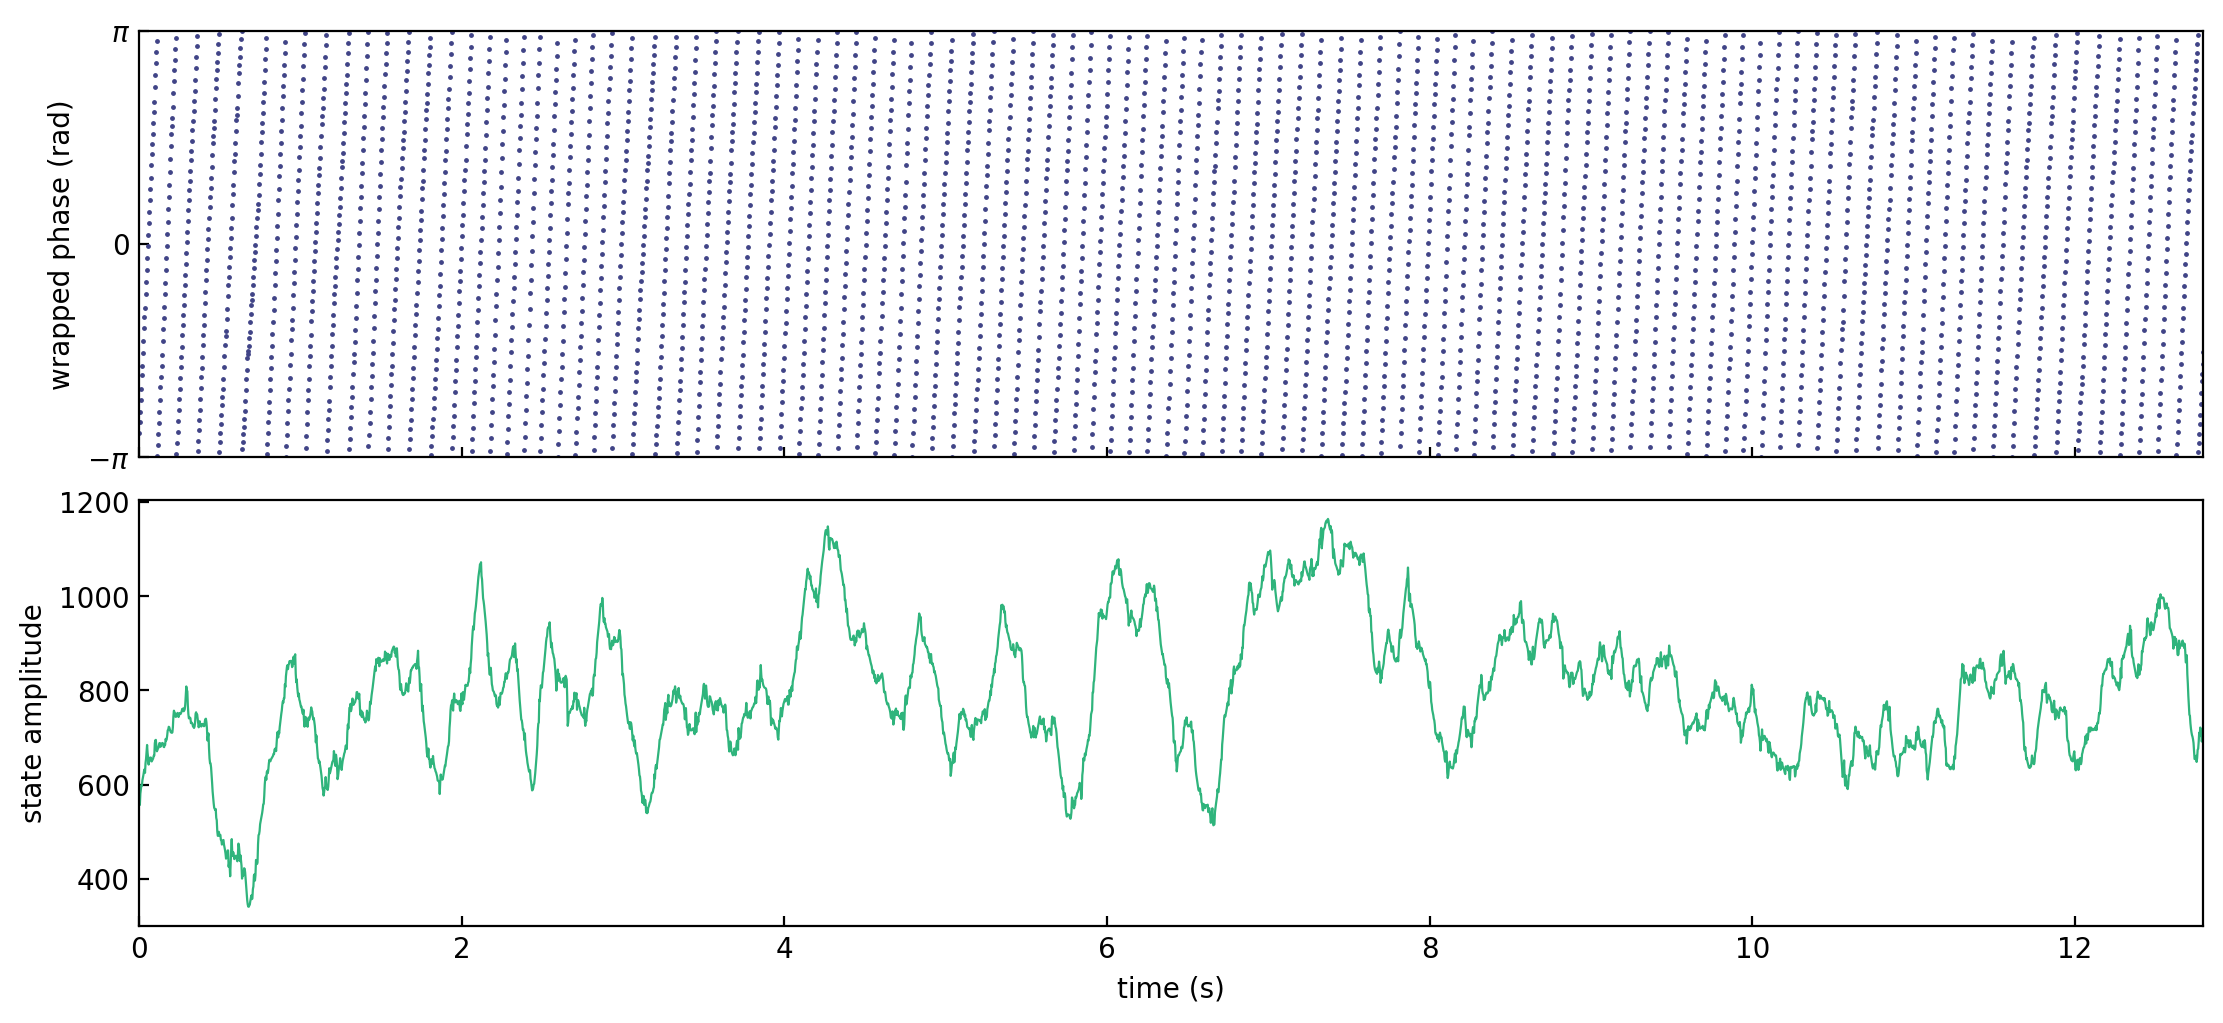

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True, constrained_layout=True)
axes[0].plot(time, mc_uncertainty['phase_wrapped'], '.', color=cmap(0.2), ms=1.5)
axes[0].set(
    ylabel='wrapped phase (rad)',
    ylim=(-np.pi, np.pi),
    yticks=(-np.pi, 0, np.pi),
    yticklabels=(r'$-\pi$', '0', r'$\pi$'),
)
axes[1].plot(time, mc_uncertainty['amplitude'], color=cmap(0.65), lw=0.8)
axes[1].set(
    xlabel='time (s)',
    ylabel='state amplitude',
    xlim=(time[0], time[-1]),
)
for ax in axes:
    ax.tick_params(direction='in')
plt.show()

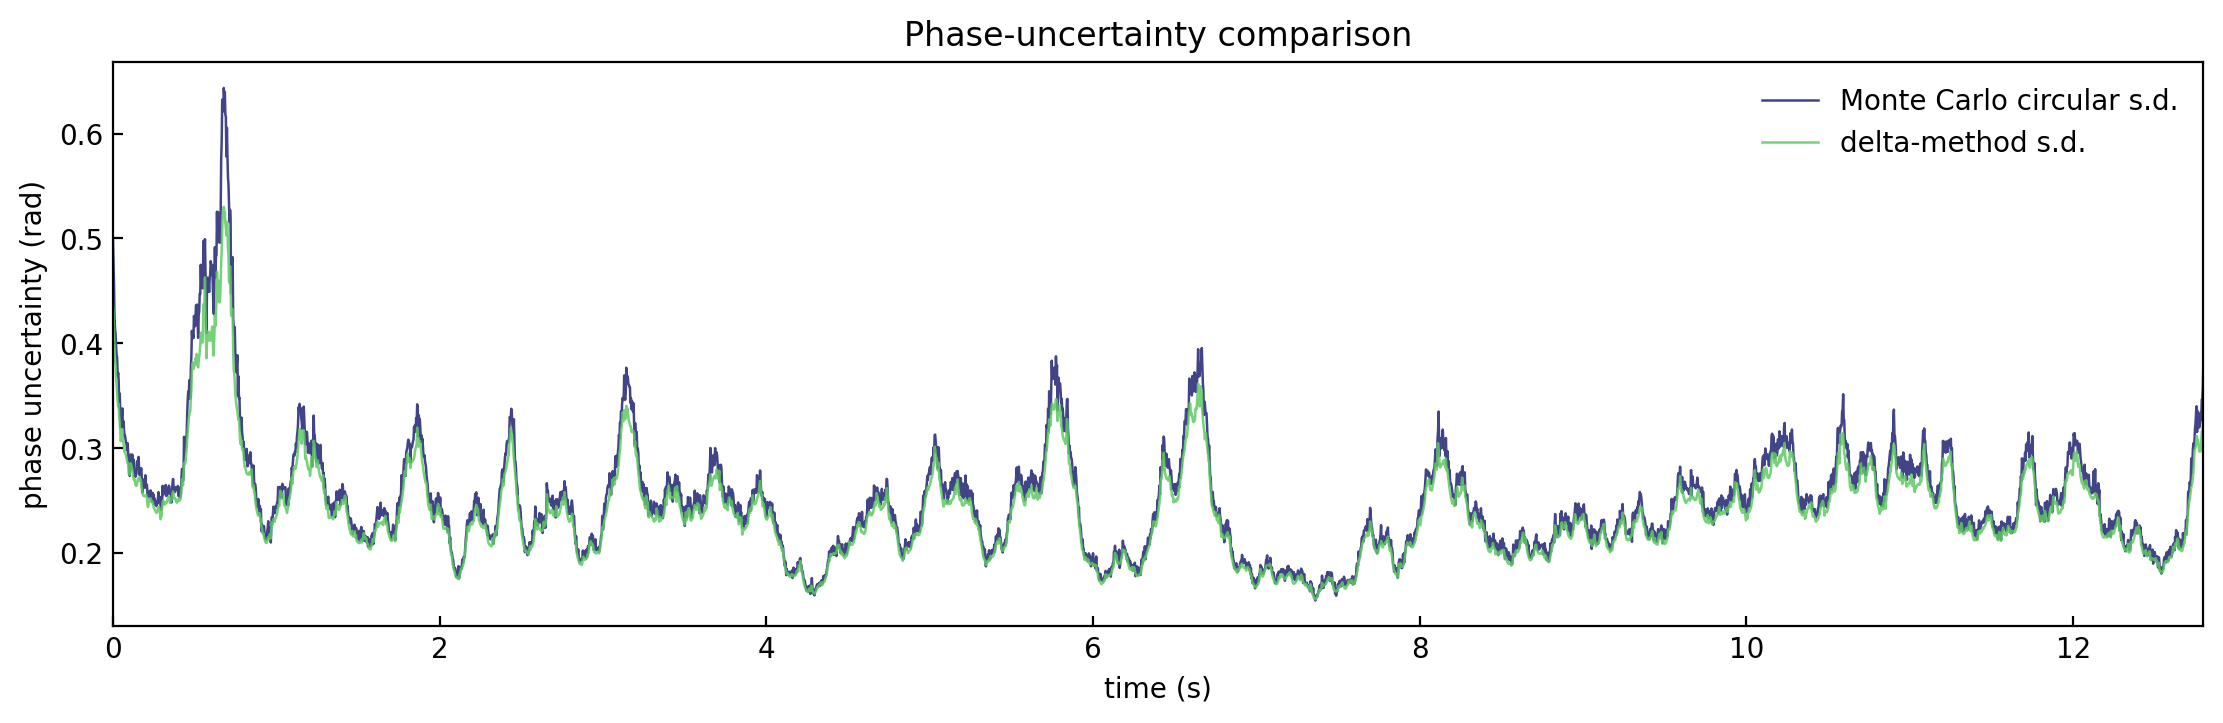

In [10]:
fig, ax = plt.subplots(figsize=(11, 3.5), constrained_layout=True)
ax.plot(
    time,
    mc_uncertainty['circular_std'],
    color=cmap(0.2),
    lw=0.9,
    label='Monte Carlo circular s.d.',
)
ax.plot(
    time,
    delta_uncertainty['phase_std'],
    color=cmap(0.75),
    lw=0.9,
    alpha=0.85,
    label='delta-method s.d.',
)
ax.set(
    xlabel='time (s)',
    ylabel='phase uncertainty (rad)',
    title='Phase-uncertainty comparison',
    xlim=(time[0], time[-1]),
)
ax.tick_params(direction='in')
ax.legend(frameon=False)
plt.show()

## Comparison with our method

The state-space observation uses the real oscillator coordinate, so phase zero is the positive cosine direction. This is the same first-harmonic gauge used by the Bayesian waveform. Consequently, only the equivalent integer-$2\pi$ unwrapping branch is selected; no continuous phase offset is fitted.

In [11]:
omega_sspe = 2 * np.pi * theta_frequency_sspe
relative_phase_sspe = mc_uncertainty['phase_unwrapped'] - omega_sspe * time
relative_quantiles_sspe = (
    mc_uncertainty['phase_quantiles'] - omega_sspe * time[:, None]
)

with np.load('../Hippocampal/data/phi_inf_data_good.npz') as inference_data:
    inference_time = inference_data['tk']
    inferred_phase_mean = inference_data['phi_inf_mean']
    inferred_phase_lo = inference_data['phi_inf_lo']
    inferred_phase_hi = inference_data['phi_inf_hi']

if not np.allclose(time, inference_time):
    raise RuntimeError('SSPE and Bayesian time grids do not match.')

branch_shift = 2 * np.pi * np.round(
    (inferred_phase_mean[0] - relative_phase_sspe[0]) / (2 * np.pi)
)
relative_phase_sspe += branch_shift
relative_quantiles_sspe += branch_shift

sspe_iqr_lo = relative_quantiles_sspe[:, 1]
sspe_iqr_hi = relative_quantiles_sspe[:, 2]

In [12]:
with np.load('../Hippocampal/data/parameter_estimates_good.npz') as parameter_data:
    map_estimate = parameter_data['map_estimate']
    parameter_names = parameter_data['parameter_names']
omega_map = map_estimate[np.flatnonzero(parameter_names == 'omega').item()]
map_frequency = omega_map / (2 * np.pi)

fft_index = 1 + np.argmax(power[1:])
fft_peak_frequency = frequencies[fft_index]

print(f'SSPE fitted frequency: {theta_frequency_sspe:.6f} Hz')
print(f'Bayesian MAP frequency: {map_frequency:.6f} Hz')
print(f'FFT peak frequency:     {fft_peak_frequency:.6f} Hz')
print(f'Branch shift:           {branch_shift / (2 * np.pi):.0f} × 2π')

SSPE fitted frequency: 8.256772 Hz
Bayesian MAP frequency: 8.255095 Hz
FFT peak frequency:     8.359375 Hz
Branch shift:           1 × 2π


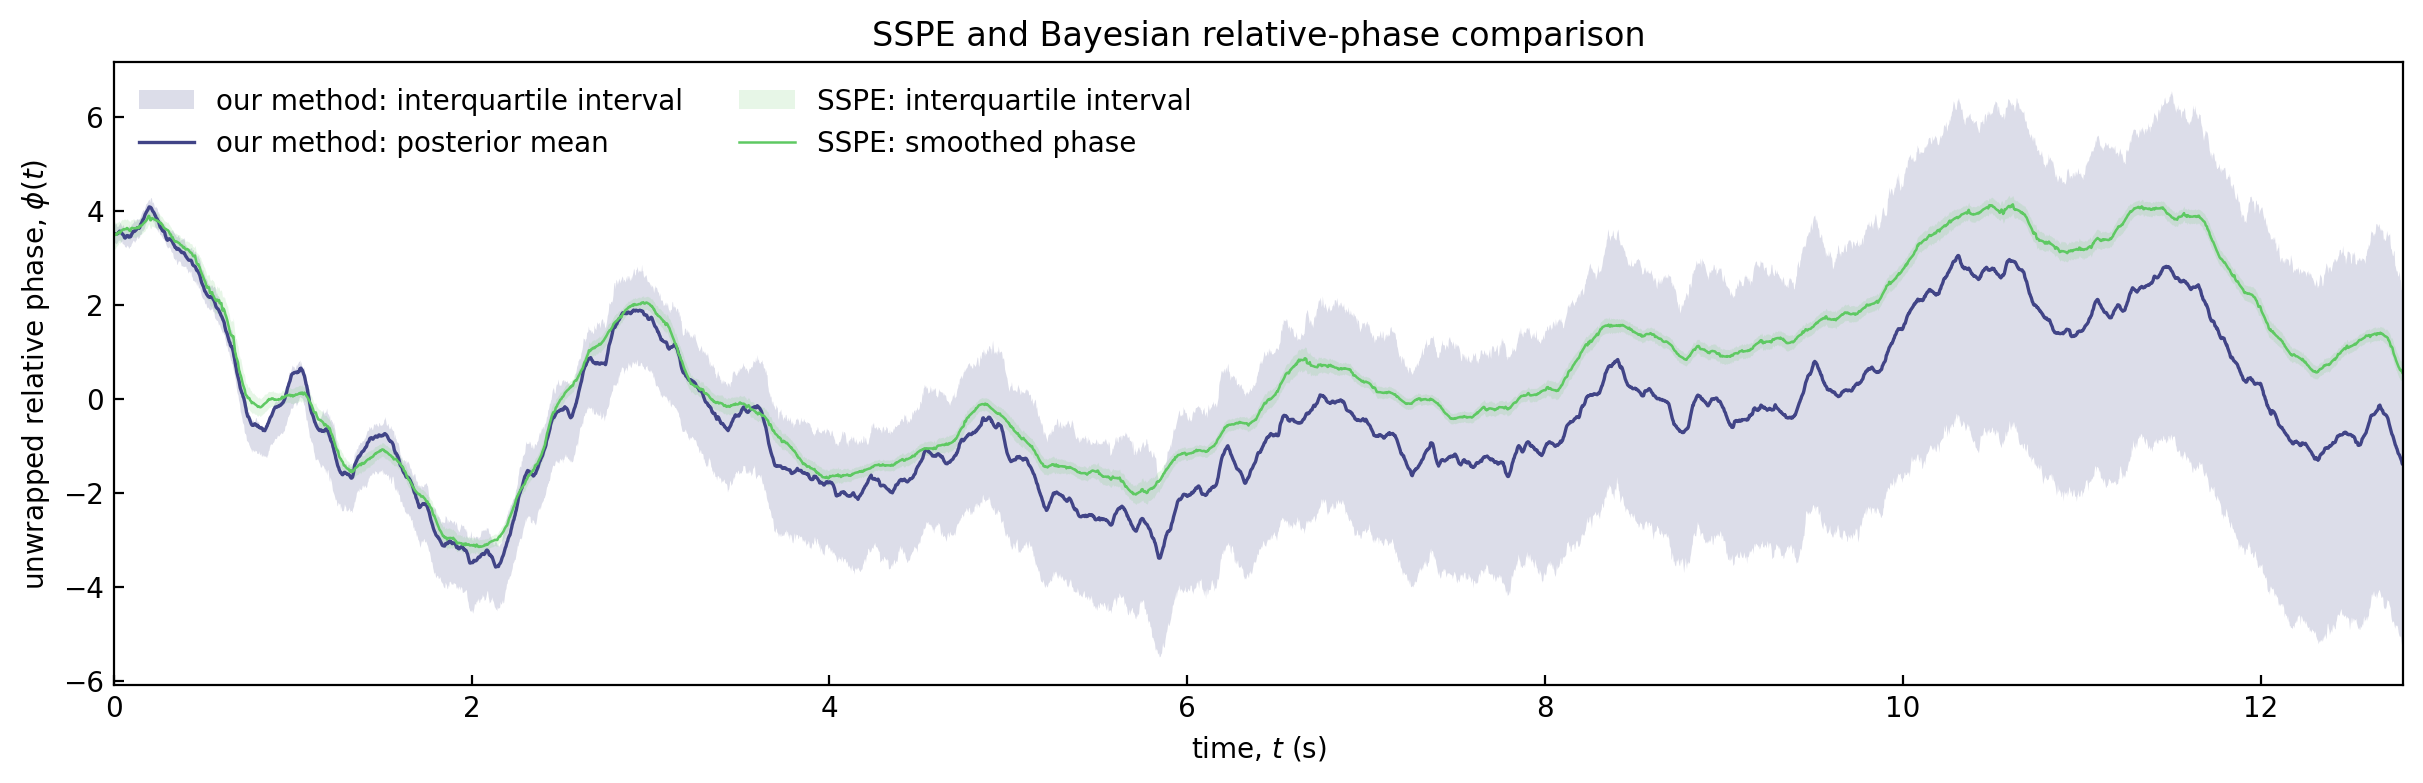

In [13]:
fig, ax = plt.subplots(figsize=(12, 3.8), constrained_layout=True)
ax.fill_between(
    time,
    inferred_phase_lo,
    inferred_phase_hi,
    color=cmap(0.2),
    alpha=0.18,
    lw=0,
    label='our method: interquartile interval',
)
ax.plot(
    time,
    inferred_phase_mean,
    color=cmap(0.2),
    lw=1.2,
    label='our method: posterior mean',
)
ax.fill_between(
    time,
    sspe_iqr_lo,
    sspe_iqr_hi,
    color=cmap(0.75),
    alpha=0.15,
    lw=0,
    label='SSPE: interquartile interval',
)
ax.plot(
    time,
    relative_phase_sspe,
    color=cmap(0.75),
    lw=0.9,
    label='SSPE: smoothed phase',
)
ax.set(
    xlabel='time, $t$ (s)',
    ylabel=r'unwrapped relative phase, $\phi(t)$',
    title='SSPE and Bayesian relative-phase comparison',
    xlim=(time[0], time[-1]),
)
ax.tick_params(direction='in')
ax.legend(frameon=False, ncol=2)
plt.show()